In [84]:
import pandas as pd

In [85]:
#Importation du dataset users_data.csv de Kaggle
users = pd.read_csv(r"C:\Users\rimla\Stage\users_data.csv")
# Afficher les premières lignes du jeu de données?
users.head()
# Afficher les informations générales sur le jeu de données
users.info()
# Afficher les statistiques descriptives des variables numériques
users.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2000 non-null   int64  
 1   current_age        2000 non-null   int64  
 2   retirement_age     2000 non-null   int64  
 3   birth_year         2000 non-null   int64  
 4   birth_month        2000 non-null   int64  
 5   gender             2000 non-null   object 
 6   address            2000 non-null   object 
 7   latitude           2000 non-null   float64
 8   longitude          2000 non-null   float64
 9   per_capita_income  2000 non-null   object 
 10  yearly_income      2000 non-null   object 
 11  total_debt         2000 non-null   object 
 12  credit_score       2000 non-null   int64  
 13  num_credit_cards   2000 non-null   int64  
dtypes: float64(2), int64(7), object(5)
memory usage: 218.9+ KB


,id,current_age,retirement_age,birth_year,birth_month,latitude,longitude,credit_score,num_credit_cards
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,999.500000,45.391500,66.237500,1973.803000,6.439000,37.389225,-91.554765,709.734500,3.073000
std,577.494589,18.414092,3.628867,18.421234,3.565338,5.114324,16.283293,67.221949,1.637379
min,0.000000,18.000000,50.000000,1918.000000,1.000000,20.880000,-159.410000,480.000000,1.000000
25%,499.750000,30.000000,65.000000,1961.000000,3.000000,33.837500,-97.395000,681.000000,2.000000
50%,999.500000,44.000000,66.000000,1975.000000,7.000000,38.250000,-86.440000,711.500000,3.000000
75%,1499.250000,58.000000,68.000000,1989.000000,10.000000,41.200000,-80.130000,753.000000,4.000000
max,1999.000000,101.000000,79.000000,2002.000000,12.000000,61.200000,-68.670000,850.000000,9.000000


In [86]:
#Afficher la taille du jeu de données
users.shape

(2000, 14)

In [87]:
#Afficher le type des variable
users.dtypes

id                     int64
current_age            int64
retirement_age         int64
birth_year             int64
birth_month            int64
gender                object
address               object
latitude             float64
longitude            float64
per_capita_income     object
yearly_income         object
total_debt            object
credit_score           int64
num_credit_cards       int64
dtype: object

In [88]:
#Vérifier les valeurs manquantes
users.isnull().sum()

id                   0
current_age          0
retirement_age       0
birth_year           0
birth_month          0
gender               0
address              0
latitude             0
longitude            0
per_capita_income    0
yearly_income        0
total_debt           0
credit_score         0
num_credit_cards     0
dtype: int64

# Aucune valeur n'est manquante

In [89]:
#Verifier les doublons
users.duplicated().sum()

0

# Il n'y a pas de doublons

In [90]:
#Choix des variables pertinentes
X = users[['current_age',
           'per_capita_income',
           'yearly_income',
           'total_debt',
           'credit_score',
           'num_credit_cards']].copy()

# Ces variables décrivent le profil financier des clients :
# - current_age : âge du client
# - per_capita_income : revenu par personne
# - yearly_income : revenu annuel
# - total_debt : dette totale
# - credit_score : score de crédit
# - num_credit_cards : nombre de cartes de crédit
# Elles sont choisies car elles permettent de regrouper les clients selon leurs caractéristiques socio-économiques et leur comportement financier.

In [91]:
#Verification du type des variables choisies
X.dtypes

current_age           int64
per_capita_income    object
yearly_income        object
total_debt           object
credit_score          int64
num_credit_cards      int64
dtype: object

In [92]:
#Transformation des variables de type object en float
X['yearly_income'] = (
    X['yearly_income']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

X['total_debt'] = (
    X['total_debt']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)
X['per_capita_income'] = (
    X['per_capita_income']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [93]:
#Verification du type après transformation
X.dtypes

current_age            int64
per_capita_income    float64
yearly_income        float64
total_debt           float64
credit_score           int64
num_credit_cards       int64
dtype: object

In [94]:
#Vérifier la corrélation entre les variables choisies
X.corr()

,current_age,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
current_age,1.000000,-0.009054,-0.114316,-0.315443,-0.005468,0.484189
per_capita_income,-0.009054,1.000000,0.963975,0.496138,-0.004545,0.018606
yearly_income,-0.114316,0.963975,1.000000,0.550641,0.000167,-0.032877
total_debt,-0.315443,0.496138,0.550641,1.000000,-0.104537,-0.217940
credit_score,-0.005468,-0.004545,0.000167,-0.104537,1.000000,0.237935
num_credit_cards,0.484189,0.018606,-0.032877,-0.217940,0.237935,1.000000


# On remarque que les variables 'yearly_income' et 'per_capita_income' présentent une très forte corrélation (proche de 1). Elles apportent donc une information redondante. Afin de limiter la redondance et d'améliorer l'interprétabilité du modèle, on supprime l'une des deux variables.

In [95]:
#Suppression de la variable per_capita_income
X = X.drop(columns=['per_capita_income'])

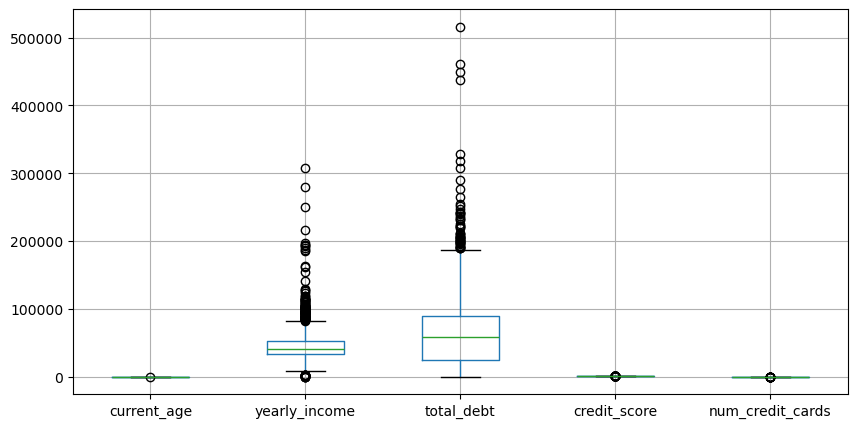

In [96]:
import matplotlib.pyplot as plt

X.boxplot(figsize=(10,5))
plt.show()

# Afficher les boîtes à moustaches des variables numériques afin de visualiser leur distribution et de détecter d'éventuelles valeurs aberrantes

In [97]:
# Normalisation des variables numériques afin qu'elles soient sur la même échelle
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Calcul de la moyenne et de l'écart-type sur les données, puis transformation des variables afin qu'elles soient centrées (moyenne = 0) et réduites (écart-type = 1)
X_scaled = scaler.fit_transform(X)

In [98]:
# Convertir les données normalisées en DataFrame afin de conserver les noms des colonnes
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [99]:
# Vérifier les statistiques descriptives après la normalisation
X_scaled.describe()

,current_age,yearly_income,total_debt,credit_score,num_credit_cards
count,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03
mean,-2.842171e-17,1.065814e-16,-5.684342e-17,-3.765876e-16,1.154632e-17
std,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00
min,-1.487901e+00,-1.988739e+00,-1.219525e+00,-3.418407e+00,-1.266364e+00
25%,-8.360635e-01,-5.610761e-01,-7.603731e-01,-4.275640e-01,-6.554793e-01
50%,-7.558603e-02,-2.162705e-01,-1.044898e-01,2.627031e-02,-4.459458e-02
75%,6.848914e-01,3.037655e-01,4.854543e-01,6.437826e-01,5.662901e-01
max,3.020644e+00,1.136745e+01,8.662735e+00,2.087125e+00,3.620714e+00


# On remarque que la moyenne (mean) est très proche de 0 et que l'écart-type (std) est proche de 1, ce qui confirme que les données ont été correctement standardisées.

# Benchmark des algorithmes de clustering
# Comparaison de K-Means et du clustering hiérarchique et DBSCAN afin de sélectionner le modèle offrant la meilleure qualité de segmentation.

In [108]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
print("Silhouette K-Means :", sil_kmeans)

c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


Silhouette K-Means : 0.2276262547603744


In [109]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=3)
labels_agg = agg.fit_predict(X_scaled)

sil_agg = silhouette_score(X_scaled, labels_agg)
print("Silhouette Hiérarchique :", sil_agg)

Silhouette Hiérarchique : 0.2017980834673615


In [112]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=10)

labels_db = dbscan.fit_predict(X_scaled)
mask = labels_db != -1

sil_db = silhouette_score(
    X_scaled[mask],
    labels_db[mask]
)

print("Silhouette DBSCAN :", sil_db)

ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)

In [113]:
pd.Series(labels_db).value_counts().sort_index()

-1     391
 0    1609
Name: count, dtype: int64

# # DBSCAN n'a pas produit une segmentation exploitable.
# L'algorithme a détecté un seul cluster et plusieurs points de bruit,
# rendant impossible l'évaluation par le score de silhouette.
# Le benchmark est donc réalisé avec K-Means et le clustering hiérarchique.

In [117]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

ch_agg = calinski_harabasz_score(X_scaled, labels_agg)
db_agg = davies_bouldin_score(X_scaled, labels_agg)

# # Calcul des indices d'évaluation
# Les performances des algorithmes sont évaluées à l'aide de trois indices :
# - Score de silhouette : mesure la cohésion des clusters et leur séparation (plus élevé = meilleur).
# - Indice de Calinski-Harabasz : compare la dispersion entre les clusters à la dispersion au sein des clusters (plus élevé = meilleur).
# - Indice de Davies-Bouldin : mesure la similarité entre les clusters (plus faible = meilleur).

In [118]:
import pandas as pd

benchmark = pd.DataFrame({
    "Algorithme": ["K-Means", "Clustering hiérarchique"],
    "Score de silhouette": [sil_k, sil_agg],
    "Indice de Calinski-Harabasz": [ch_k, ch_agg],
    "Indice de Davies-Bouldin": [db_k, db_agg]
}).round(3)

benchmark

,Algorithme,Score de silhouette,Indice de Calinski-Harabasz,Indice de Davies-Bouldin
0,K-Means,0.228,549.728,1.467
1,Clustering hiérarchique,0.202,414.857,1.498


# Comparaison des algorithmes de clustering
# Les métriques calculées permettent d'évaluer et de comparer la qualité des partitions obtenues par K-Means et le clustering hiérarchique.
# Le modèle le plus performant sera sélectionné pour la segmentation des clients c'est donc K-means.

# On commence l'application du modèle K-means et on commence par le choix de K à l'aide de la méthode du coude

In [100]:
from sklearn.cluster import KMeans

inertias = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Window

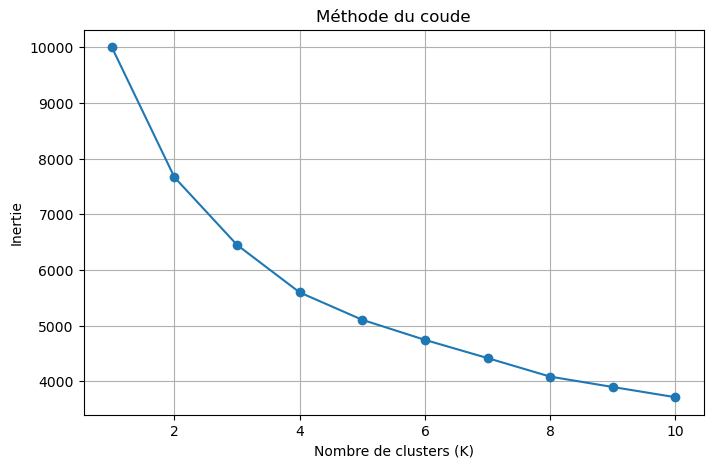

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(range(1,11), inertias, marker='o')
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.grid(True)
plt.show()

# La méthode du coude consiste à calculer l'inertie pour plusieurs valeurs de K et à tracer son évolution. Le nombre optimal de clusters correspond au point où la diminution de l'inertie devient moins importante, formant un « coude » sur la courbe.

# La méthode de coude ne présente pas une estimation exacte du nombre de cluster adapté(ce serait entre 3 et 5 ) donc on utilise la méthode de silhouette

In [119]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)
    print(f"K = {k} | Score de silhouette = {score:.4f}")

c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 2 | Score de silhouette = 0.2252


c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 3 | Score de silhouette = 0.2276


c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


...

K = 8 | Score de silhouette = 0.1800


c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 9 | Score de silhouette = 0.1799


c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


K = 10 | Score de silhouette = 0.1728


# La méthode de silhouette évalue la qualité du partitionnement en mesurant la cohésion des observations au sein de leur cluster et leur séparation par rapport aux autres clusters. La valeur de K qui obtient le score de silhouette le plus élevé est généralement retenue comme le meilleur choix.Ici on trouve K=3

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42) # random_state permet de fixer l'initialisation aléatoire des centroïdes

kmeans.fit(X_scaled)

c:\Users\rimla\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


KMeans(n_clusters=3, random_state=42)

In [104]:
# Associer chaque client au cluster correspondant
X["cluster"] = kmeans.predict(X_scaled)

In [ ]:
#Nombre de clients dans chaque cluster
X["cluster"].value_counts()

cluster
0    1015
1     728
2     257
Name: count, dtype: int64

In [ ]:
#Moyenne des 5 variables par clusters
X.groupby("cluster")[[
    "current_age",
    "yearly_income",
    "total_debt",
    "credit_score",
    "num_credit_cards"
]].mean()

,current_age,yearly_income,total_debt,credit_score,num_credit_cards
cluster,,,,,
0,34.802956,41298.788177,62341.717241,698.618719,2.175369
1,62.041209,39242.114011,34592.178571,727.973901,4.458791
2,40.046693,81498.968872,151593.147860,701.968872,2.692607
